# IRIS: the full pipeline in one notebook

This notebook joins the six project notebooks so the whole analysis runs top to bottom with **Run All**. Each part
keeps its original notebook's text and code, and its first cell sets up its own paths and data, so a part can
also be rerun on its own after the parts before it have run once.

| Part | Original notebook | What it does |
| --- | --- | --- |
| 1 | `01_prepare_data.ipynb` | Prepare the rain and case data |
| 2 | `03_metro_manila_flood.ipynb` | Metro Manila flood drill-down |
| 3 | `00_eda.ipynb` | Exploratory data analysis |
| 4 | `02_lag_analysis.ipynb` | Lag analysis |
| 5 | `04_metro_manila_outlook.ipynb` | Metro Manila outlook |
| 6 | `05_forecast_backtest.ipynb` | Forecast backtest |

**Before you run it.** Put the raw files in `datasets/` (see the README): `phl-rainfall-subnat-full.csv`,
`Diseases Data (for NBL).xlsx`, `phl_admin_boundaries.gdb/`, `MetroManila_Flood_100year.shp` (with its .dbf, .shx
and .prj) and `2020-census-total-popn_single-age_malefemale_admin4.xlsx`. The next cell checks they are there.

**Run time.** About 10 to 15 minutes in all; the flood overlay in Part 2 takes most of it.

**What it writes.** The files in `data/processed/` that the dashboard reads. Running it again overwrites them with
the same results. `provinces.geojson` is only rebuilt if it is missing.

The separate notebooks are still the source: after editing one, rebuild this file with
`python tools/build_full_notebook.py`.

In [1]:
# Check that the raw files are in place before the long run starts
from pathlib import Path

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
RAW = ROOT / 'datasets'
NEEDED = ['phl-rainfall-subnat-full.csv', 'Diseases Data (for NBL).xlsx', 'phl_admin_boundaries.gdb',
          'MetroManila_Flood_100year.shp', 'MetroManila_Flood_100year.dbf', 'MetroManila_Flood_100year.shx',
          'MetroManila_Flood_100year.prj', '2020-census-total-popn_single-age_malefemale_admin4.xlsx']
missing = [f for f in NEEDED if not (RAW / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing from {RAW.resolve()}: ' + ', '.join(missing))
print('All raw files found in', RAW.resolve())

All raw files found in /tmp/claude-0/-home-user/199f8711-536b-5d00-8a89-4eb98a94e7a5/scratchpad/full/datasets


---
# Part 1: Prepare the rain and case data

*From `notebooks/01_prepare_data.ipynb`.*

Turns the raw rainfall, disease and boundary files into the small files the dashboard and the later notebooks read.

| Output (in `data/processed/`) | What it holds |
| --- | --- |
| `dekad_rain.csv` | 10-day rainfall per province since 2015 with each province's own 90th percentile; Metro Manila's row drives the rainfall alert |
| `province_weekly_p90.csv` | Each province's 90th percentile of weekly rain, used to score the live forecast |
| `weekly_national.csv` | The weekly national rain signal joined to weekly leptospirosis cases, for the lag analysis |
| `provinces.geojson` | Simplified province shapes keyed by `PCODE`, used in notebook 04 to place one forecast point per province (optional step, needs the boundary geodatabase) |

**Why all provinces, for a Metro Manila tool?** Leptospirosis case counts are only open at the national level, so
the rain signal that is matched to them has to be national too: the share of provinces with an extreme week.

**Province units.** The rainfall file uses 81 units with codes like `PH01028`. NCR is one unit (`PH13074`).

Run top to bottom. On Colab, run the setup cell first and point `RAW` at the uploaded `datasets` folder.

In [2]:
# Setup. On Colab, uncomment the Drive lines and set RAW to the datasets folder.
# from google.colab import drive
# drive.mount('/content/drive')
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')   # project folder
RAW = ROOT / 'datasets'          # on Colab, e.g. Path('/content/drive/MyDrive/IRIS/datasets')
OUT = ROOT / 'data' / 'processed'
OUT.mkdir(parents=True, exist_ok=True)

RAIN_CSV = RAW / 'phl-rainfall-subnat-full.csv'
DISEASE_XLSX = RAW / 'Diseases Data (for NBL).xlsx'
BOUNDARY_GDB = RAW / 'phl_admin_boundaries.gdb'   # folder, or the downloaded .gdb.zip

BASELINE = (1981, 2024)   # full years used for percentiles and thresholds
TRIGGER_FROM = '2015-01-01'

## 1. Rainfall

Keep the province rows (`adm_level == 2`). `rfh` is the 10-day (dekad) rainfall total in mm and `r1h` is the
rolling 1-month total, which stands in for the 30-day total in the proposal. The last two dekads are marked
`prelim` by the publisher; they are kept for the trigger but left out of the baseline.

In [3]:
rain = pd.read_csv(RAIN_CSV, parse_dates=['date'])
rain = rain[rain['adm_level'] == 2][['date', 'PCODE', 'n_pixels', 'rfh', 'rfh_avg', 'r1h', 'version']].copy()
UNITS = sorted(rain['PCODE'].unique())
print(len(UNITS), 'province units;', rain['date'].min().date(), 'to', rain['date'].max().date())
base = rain[rain['date'].dt.year.between(*BASELINE) & (rain['version'] == 'final')]

81 province units; 1981-01-01 to 2026-10-11


## 2. Trigger table for the dashboard

Each province's own 90th percentile of 10-day rainfall (baseline years) is the alert threshold. The table keeps
dekads from 2015 on so the app stays small.

In [4]:
p90 = base.groupby('PCODE')['rfh'].quantile(0.90).rename('p90_mm')
trig = rain[rain['date'] >= TRIGGER_FROM].join(p90, on='PCODE')
trig['above_p90'] = trig['rfh'] > trig['p90_mm']
trig = trig[['date', 'PCODE', 'rfh', 'rfh_avg', 'p90_mm', 'above_p90', 'version']].round({'rfh': 2, 'rfh_avg': 2, 'p90_mm': 2})
trig.to_csv(OUT / 'dekad_rain.csv', index=False)
print(len(trig), 'rows; latest dekad', trig['date'].max().date(),
      '| provinces above p90 then:', int(trig.loc[trig['date'] == trig['date'].max(), 'above_p90'].sum()))

34425 rows; latest dekad 2026-10-11 | provinces above p90 then: 2


## 3. Weekly national series for the lag analysis

Each dekad total is spread evenly over its days (dekad 3 runs 8 to 11 days), summed into ISO weeks per
province, and then summarized nationally: the share of provinces above their own weekly 90th percentile and the
mean weekly rainfall. Weekly leptospirosis counts (2019 to 2023 in this file) are reshaped to year and week and
joined on ISO year and week, which approximates DOH morbidity weeks. Missing weeks stay missing.

In [5]:
r = rain[['date', 'PCODE', 'rfh']].copy()
nxt = r['date'] + pd.offsets.MonthBegin(1)
r['end'] = np.where(r['date'].dt.day == 21, nxt, r['date'] + pd.Timedelta(days=10))
r['ndays'] = (pd.to_datetime(r['end']) - r['date']).dt.days
daily = r.loc[r.index.repeat(r['ndays'])].copy()
daily['day'] = daily['date'] + pd.to_timedelta(daily.groupby(level=0).cumcount(), unit='D')
daily['mm'] = daily['rfh'] / daily['ndays']
iso = daily['day'].dt.isocalendar()
daily['iso_year'], daily['iso_week'] = iso['year'].astype(int), iso['week'].astype(int)

wk = daily.groupby(['PCODE', 'iso_year', 'iso_week'])['mm'].agg(['sum', 'size']).reset_index()
wk = wk[wk['size'] == 7]                                   # drop partial weeks at the ends
wk_p90 = wk[wk['iso_year'].between(*BASELINE)].groupby('PCODE')['sum'].quantile(0.90)
wk_p90.rename('weekly_p90_mm').round(2).to_csv(OUT / 'province_weekly_p90.csv')   # used by the live forecast
wk['above'] = wk['sum'] > wk['PCODE'].map(wk_p90)
nat = wk.groupby(['iso_year', 'iso_week']).agg(
    share_prov_above_p90=('above', 'mean'), mean_rain_mm=('sum', 'mean')).reset_index()

dis = pd.read_excel(DISEASE_XLSX)
lep = [c for c in dis.columns if c.lower().startswith('leptospirosis')]
lepto = (dis[['Week'] + lep].dropna(subset=['Week'])
         .melt(id_vars='Week', var_name='col', value_name='cases'))
lepto['iso_year'] = lepto['col'].str[-4:].astype(int)
lepto['iso_week'] = lepto['Week'].astype(int)
lepto = lepto[['iso_year', 'iso_week', 'cases']]

weekly = nat.merge(lepto, on=['iso_year', 'iso_week'], how='left')
weekly = weekly[weekly['iso_year'] >= lepto['iso_year'].min() - 1]
weekly['week_start'] = pd.to_datetime(
    weekly['iso_year'].astype(str) + weekly['iso_week'].astype(str).str.zfill(2) + '1', format='%G%V%u')
weekly['covid_period'] = weekly['iso_year'].isin([2020, 2021])
weekly.round({'share_prov_above_p90': 4, 'mean_rain_mm': 2}).to_csv(OUT / 'weekly_national.csv', index=False)
print(weekly['cases'].notna().sum(), 'weeks with case counts;',
      weekly.groupby('iso_year')['cases'].count().to_dict())

227 weeks with case counts; {2018: 0, 2019: 52, 2020: 28, 2021: 52, 2022: 52, 2023: 43, 2024: 0, 2025: 0, 2026: 0}


## 4. Province shapes (optional)

Skip this if `provinces.geojson` is already in `data/processed/`. It reads only the province layer of the
boundary geodatabase, merges the 2025 units into the 81 rainfall units and simplifies the shapes to about 1 MB. Notebook 04 uses them
to place one rainfall forecast point in each province.
Needs `geopandas` (preinstalled on Colab).

In [6]:
RUN_GEO = not (OUT / 'provinces.geojson').exists()
if RUN_GEO:
    import geopandas as gpd
    shp = gpd.read_file(BOUNDARY_GDB, layer='phl_admin2', columns=['adm2_pcode'])
    MERGE = {'PH13039': 'PH13074', 'PH13075': 'PH13074', 'PH13076': 'PH13074', 'PH09097': 'PH19007',
             'PH11086': 'PH11024', 'PH19088': 'PH19087', 'PH19099': 'PH19087'}
    shp['PCODE'] = shp['adm2_pcode'].replace(MERGE)
    assert set(shp['PCODE']) == set(UNITS)
    shp = shp.dissolve('PCODE').reset_index()[['PCODE', 'geometry']].to_crs(4326)
    shp['geometry'] = shp.simplify(0.01, preserve_topology=True)
    shp.to_file(OUT / 'provinces.geojson', driver='GeoJSON')
print(sorted(p.name for p in OUT.iterdir()))

/tmp/claude-0/-home-user/199f8711-536b-5d00-8a89-4eb98a94e7a5/scratchpad/repo/.v/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP.
  return ogr_read(


['dekad_rain.csv', 'disease_lag.csv', 'event_study.csv', 'forecast_alpha.csv', 'forecast_backtest.csv', 'forecast_coefs.csv', 'forecast_scores.csv', 'forecast_snapshot_ncr.csv', 'forecast_snapshot_share.csv', 'lag_curve.png', 'lag_results.csv', 'ncr_barangays.geojson', 'ncr_flood_events.csv', 'ncr_month_outlook.csv', 'province_points.csv', 'province_weekly_p90.csv', 'provinces.geojson', 'weekly_case_baseline.csv', 'weekly_national.csv']


---
# Part 2: Metro Manila flood drill-down

*From `notebooks/03_metro_manila_flood.ipynb`.*

Two barangays in the same city get the same rain but not the same flood. This notebook overlays the UP NOAH
100-year flood hazard map for Metro Manila on the 2025 barangay boundaries and the 2020 census ages, and estimates
how many people, and how many children under 5 and adults 65+, live in medium or high flood hazard zones.

- Flood hazard: UP NOAH Center, Metro Manila 100-year flood hazard (`Var` 1 = low, 2 = medium, 3 = high).
  Save the downloaded zip's contents as `datasets/MetroManila_Flood_100year.shp` (with its .dbf, .shx, .prj).
- People in a hazard zone are estimated by area share (population spread evenly over each barangay), which is
  a simplification: settlements are not spread evenly.

Output: `data/processed/ncr_barangays.geojson`. The overlay takes about 5 to 10 minutes.

In [7]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
RAW, OUT = ROOT / 'datasets', ROOT / 'data' / 'processed'
UTM = 32651   # metres, for areas

bgy = gpd.read_file(RAW / 'phl_admin_boundaries.gdb', layer='phl_admin4', where="adm1_pcode='PH13'")
bgy = bgy[['adm4_name', 'adm4_pcode', 'adm3_name', 'geometry']].to_crs(UTM)
bgy['area'] = bgy.area
flood = gpd.read_file(RAW / 'MetroManila_Flood_100year.shp').to_crs(UTM)
print(len(bgy), 'barangays;', flood['Var'].tolist(), 'hazard levels')

1712 barangays; [1.0, 2.0, 3.0] hazard levels


In [8]:
ov = gpd.overlay(bgy[['adm4_pcode', 'geometry']], flood, how='intersection', keep_geom_type=True)
ov['a'] = ov.area
share = ov.pivot_table(index='adm4_pcode', columns='Var', values='a', aggfunc='sum').fillna(0)
share.columns = [f'share_var{int(v)}' for v in share.columns]
bgy = bgy.merge(share, left_on='adm4_pcode', right_index=True, how='left')
for v in (1, 2, 3):
    bgy[f'share_var{v}'] = (bgy[f'share_var{v}'].fillna(0) / bgy['area']).clip(0, 1)
bgy[['share_var1', 'share_var2', 'share_var3']].describe().round(3)

,share_var1,share_var2,share_var3
count,1712.000,1712.000,1712.000
mean,0.209,0.359,0.058
std,0.165,0.307,0.129
min,0.000,0.000,0.000
25%,0.077,0.077,0.000
50%,0.172,0.275,0.000
75%,0.311,0.621,0.060
max,0.859,1.000,1.000


Census barangays are matched on code (`PH` + region + `0` + the rest of the old 9-digit code), and the City of
Manila's barangays, whose codes changed, by city and barangay name.

In [9]:
census = pd.read_excel(RAW / '2020-census-total-popn_single-age_malefemale_admin4.xlsx', engine='openpyxl')
census = census[census['BgyCode_old'].str.startswith('PH13')].copy()
U5 = ['Under 1_MF', '1_MF', '2_MF', '3_MF', '4_MF']
O65 = [f'{a}_MF' for a in range(65, 80)] + ['80 and Over_MF']
census[U5 + O65 + ['Total_MF']] = census[U5 + O65 + ['Total_MF']].replace('-', 0).apply(pd.to_numeric).fillna(0)
census['under5'], census['over65'] = census[U5].sum(axis=1), census[O65].sum(axis=1)
MANILA = {'TONDO I/II', 'BINONDO', 'QUIAPO', 'SAN NICOLAS', 'SANTA CRUZ', 'SAMPALOC', 'SAN MIGUEL', 'ERMITA',
          'INTRAMUROS', 'MALATE', 'PACO', 'PANDACAN', 'PORT AREA', 'SANTA ANA'}
norm = lambda s: re.sub(r'[^a-z0-9]', '', str(s).lower().replace('barangay', '').replace('poblacion', 'pob'))
city = lambda s: s.str.upper().str.replace('CITY OF ', '').str.replace(' CITY', '')
census['city'] = np.where(census['Mun'].isin(MANILA), 'MANILA', city(census['Mun']))
census['nk'] = census['city'] + '|' + census['Bgy'].map(norm)
census['key'] = 'PH' + census['BgyCode_old'].str[2:4] + '0' + census['BgyCode_old'].str[4:]
bgy['nk'] = city(bgy['adm3_name']) + '|' + bgy['adm4_name'].map(norm)

cols = ['Total_MF', 'under5', 'over65']
bgy = bgy.merge(census[['key'] + cols], left_on='adm4_pcode', right_on='key', how='left')
by_name = census.drop_duplicates('nk').set_index('nk')[cols]
miss = bgy['Total_MF'].isna()
for c in cols:
    bgy.loc[miss, c] = bgy.loc[miss, 'nk'].map(by_name[c])
print('Unmatched:', bgy.loc[bgy['Total_MF'].isna(), 'adm4_name'].tolist())   # cemetery and mall areas, no residents

Unmatched: ['Manila North Cemetery', 'Tutuban Mall (Claimed by Five Barangays of Tondo, Manila)']


In [10]:
b = bgy[bgy['Total_MF'].notna()].copy()
b['vulnerable'] = b['under5'] + b['over65']
b['flood_share_any'] = (b['share_var1'] + b['share_var2'] + b['share_var3']).clip(0, 1)
b['flood_share_med_high'] = (b['share_var2'] + b['share_var3']).clip(0, 1)
b['people_med_high'] = (b['Total_MF'] * b['flood_share_med_high']).round(0)
b['vulnerable_med_high'] = (b['vulnerable'] * b['flood_share_med_high']).round(0)
b['rank'] = b['vulnerable_med_high'].rank(ascending=False, method='min').astype(int)
b['geometry'] = b.simplify(12, preserve_topology=True)
out = b.rename(columns={'adm4_pcode': 'bgy_code', 'adm4_name': 'barangay', 'adm3_name': 'city',
                        'Total_MF': 'population'})[
    ['bgy_code', 'barangay', 'city', 'population', 'under5', 'over65', 'vulnerable', 'share_var1', 'share_var2',
     'share_var3', 'flood_share_any', 'flood_share_med_high', 'people_med_high', 'vulnerable_med_high', 'rank',
     'geometry']].to_crs(4326)
for c in ['share_var1', 'share_var2', 'share_var3', 'flood_share_any', 'flood_share_med_high']:
    out[c] = out[c].round(3)
for c in ['population', 'under5', 'over65', 'vulnerable']:
    out[c] = out[c].astype(int)
out.to_file(OUT / 'ncr_barangays.geojson', driver='GeoJSON', COORDINATE_PRECISION=5)
print(f"{out['people_med_high'].sum():,.0f} people, {out['vulnerable_med_high'].sum():,.0f} of them under 5 or 65+, "
      "live in medium or high flood hazard zones")
out.sort_values('rank').head(10)[['barangay', 'city', 'population', 'flood_share_med_high', 'vulnerable_med_high']]

4,244,429 people, 606,567 of them under 5 or 65+, live in medium or high flood hazard zones


,barangay,city,population,flood_share_med_high,vulnerable_med_high
956,Pinagbuhatan,City of Pasig,163598,0.475,11433.0
952,Manggahan,City of Pasig,88078,0.731,9528.0
958,Rosario,City of Pasig,73979,0.870,9103.0
930,Malanday,City of Marikina,53886,0.930,7520.0
1110,Batasan Hills,Quezon City,166572,0.310,7444.0
1460,San Dionisio,City of Parañaque,72522,0.609,6626.0
968,Santolan,City of Pasig,57933,0.757,6459.0
931,Nangka,City of Marikina,43368,0.956,6360.0
953,Maybunga,City of Pasig,45555,0.935,6191.0
981,Bagong Silangan,Quezon City,106886,0.367,5983.0


---
# Part 3: Exploratory data analysis

*From `notebooks/00_eda.ipynb`.*

A first look at the data before any modelling: how rain and cases are distributed, what is missing, which weeks
stand out, how both follow the seasons, and whether rain and cases move together at all. Each section ends with
what we saw and how it shaped notebooks 01 to 05.

Runs on the small files in `data/processed/` (made in Parts 1 and 2 above).

| File | What it holds |
| --- | --- |
| `weekly_national.csv` | ISO weeks 2018 to 2026: share of the 81 provinces with an extreme week, mean rain, national leptospirosis cases (2019 to 2023 only) |
| `dekad_rain.csv` | CHIRPS 10-day rain for the 81 provinces, 2015 to 2026 (1981 onwards was used to set the thresholds) |
| `ncr_barangays.geojson` | 1,710 Metro Manila barangays with population, ages and flood-zone shares |

In [11]:
import matplotlib
_style_before = matplotlib.rcParams.copy()   # restored at the end of this part

In [12]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
DATA = ROOT / 'data' / 'processed'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
RED, BLUE, GREY = '#c1121f', '#2a6f97', '#9e9e9e'

w = pd.read_csv(DATA / 'weekly_national.csv').sort_values(['iso_year', 'iso_week']).reset_index(drop=True)
rain = pd.read_csv(DATA / 'dekad_rain.csv', parse_dates=['date'])
ncr = rain[rain['PCODE'] == 'PH13074'].sort_values('date')
geo = json.loads((DATA / 'ncr_barangays.geojson').read_text())
bgy = pd.DataFrame([f['properties'] for f in geo['features']])
c = w[w['iso_year'].between(2019, 2023)].copy()   # the years with case data
print(f'{len(w)} weeks of rain, {len(c)} weeks in 2019 to 2023, {rain.PCODE.nunique()} provinces, {len(bgy)} barangays')

459 weeks of rain, 261 weeks in 2019 to 2023, 81 provinces, 1710 barangays


## 1. Rain

Missing values: 0 | preliminary periods: 162 of 34425 | Metro Manila: median 43 mm, max 553 mm


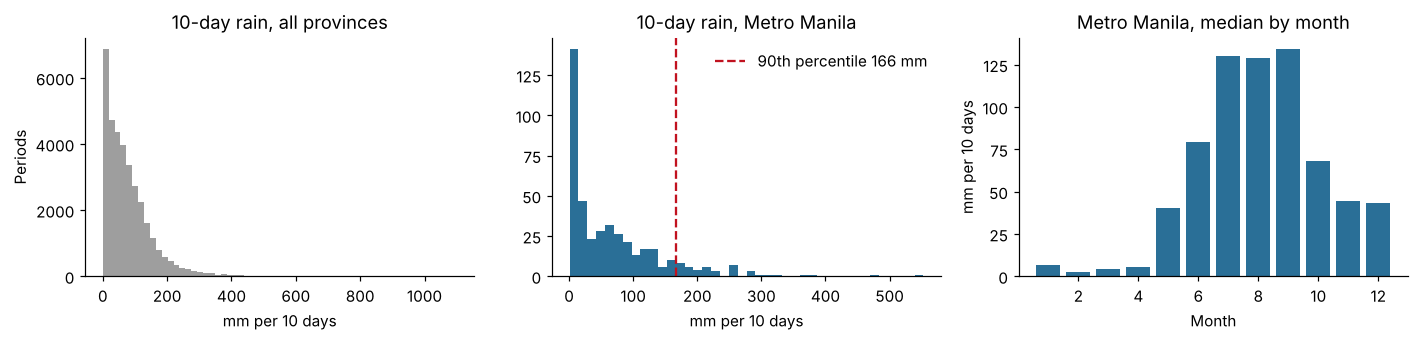

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(rain['rfh'], bins=60, color=GREY)
ax[0].set(title='10-day rain, all provinces', xlabel='mm per 10 days', ylabel='Periods')
ax[1].hist(ncr['rfh'], bins=40, color=BLUE)
ax[1].axvline(ncr['p90_mm'].iloc[0], color=RED, ls='--', label=f"90th percentile {ncr['p90_mm'].iloc[0]:.0f} mm")
ax[1].set(title='10-day rain, Metro Manila', xlabel='mm per 10 days'); ax[1].legend(frameon=False)
m = ncr.assign(month=ncr['date'].dt.month).groupby('month')['rfh']
ax[2].bar(m.median().index, m.median(), color=BLUE); ax[2].set(title='Metro Manila, median by month', xlabel='Month', ylabel='mm per 10 days')
fig.tight_layout()
print('Missing values:', int(rain.isna().sum().sum()), '| preliminary periods:', int((rain['version'] == 'prelim').sum()),
      f"of {len(rain)} | Metro Manila: median {ncr['rfh'].median():.0f} mm, max {ncr['rfh'].max():.0f} mm")

**What we saw.** Rain is strongly right-skewed: most 10-day periods are dry or moderate, and a few are extreme
(over 500 mm in Metro Manila). There are no missing values, and only the newest periods are preliminary. Rain is
low from January to April and peaks from July to September.

**How it shaped the work.**
- A skewed variable with rare extremes is better summarised by a percentile than by an average, so the alert uses
  each place's own **90th percentile** (notebook 01), not a fixed mm value.
- Provinces differ a lot in how much rain is normal, so the national rain signal counts the **share of provinces
  above their own 90th percentile**, not mean mm (mean mm is kept as a sensitivity check in notebook 02).
- The app warns when a period is preliminary, since WFP may revise it.

## 2. Leptospirosis cases: gaps, zeros and outliers

,weeks_reported,total,mean_per_week,median,max,weeks_missing
iso_year,,,,,,
2019,52,3278.0,63.0,41.5,229.0,0
2020,28,1427.0,51.0,26.0,368.0,25
2021,52,1617.0,31.1,19.0,204.0,0
2022,52,4773.0,91.8,49.5,408.0,0
2023,43,5511.0,128.2,91.0,373.0,9


Weeks with 0 cases: [[2019, 10], [2021, 11], [2021, 20], [2022, 19]]
Variance / mean of weekly cases: 88 (1 would fit a Poisson count)


,iso_year,iso_week,week_start,cases,share_prov_above_p90
152,2020,49,2020-11-30,368.0,0.1481
254,2022,46,2022-11-14,315.0,0.1235
260,2022,52,2022-12-26,408.0,0.2840
292,2023,32,2023-08-07,356.0,0.0123
293,2023,33,2023-08-14,373.0,0.1728
297,2023,37,2023-09-11,315.0,0.0988


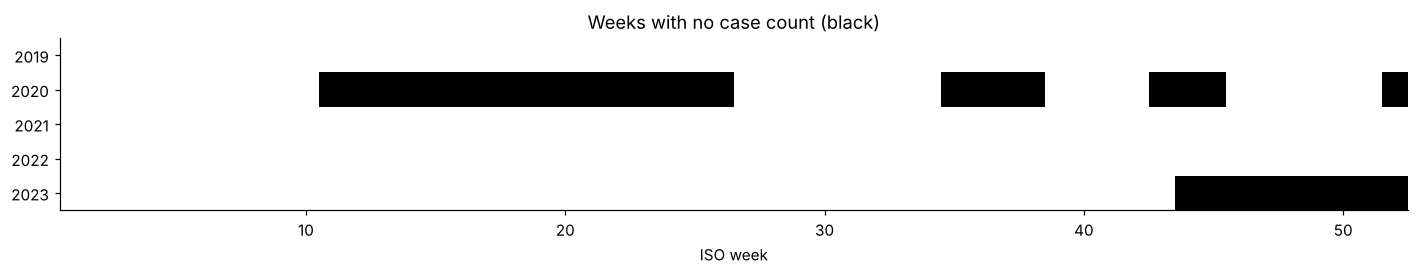

In [14]:
yr = c.groupby('iso_year')['cases'].agg(weeks_reported='count', total='sum', mean_per_week='mean', median='median', max='max')
yr['weeks_missing'] = c.groupby('iso_year')['cases'].apply(lambda s: s.isna().sum())
display(yr.round(1))
grid = c.pivot(index='iso_year', columns='iso_week', values='cases').loc[:, 1:52]   # only 2020 has a week 53
fig, ax = plt.subplots(figsize=(13, 2.6))
ax.imshow(grid.isna(), aspect='auto', cmap='Greys', interpolation='none', extent=[0.5, 52.5, len(grid) - 0.5, -0.5])
ax.set(yticks=range(len(grid)), yticklabels=grid.index, xlabel='ISO week', title='Weeks with no case count (black)')
fig.tight_layout()
q1, q3 = c['cases'].quantile([0.25, 0.75])
print('Weeks with 0 cases:', c.loc[c['cases'] == 0, ['iso_year', 'iso_week']].values.tolist())
print(f"Variance / mean of weekly cases: {c['cases'].var() / c['cases'].mean():.0f} (1 would fit a Poisson count)")
c.loc[c['cases'] > q3 + 3 * (q3 - q1), ['iso_year', 'iso_week', 'week_start', 'cases', 'share_prov_above_p90']]

**What we saw.**
- **Reporting gaps:** 25 weeks are missing in 2020, from March onward during the COVID lockdowns, and 9 at the end of 2023 (weeks 44
  to 52, not yet in the compiled file). The other years are complete. Four weeks report 0 cases, which is more
  likely a reporting gap than a true zero.
- **Year levels shift a lot:** average weekly cases went from 63 (2019) to 31 (2021) to 128 (2023). This reflects
  reporting and testing as much as disease.
- **Overdispersion:** the variance is about 88 times the mean, far more than a Poisson count allows.
- **Outlier weeks** (above Q3 + 3 × IQR) all fall from August to December, the season after the heavy rains,
  so they look like real surges, not errors. We kept them.

**How it shaped the work.**
- Missing weeks are left out, never filled with 0 (notebooks 01 and 02); the model uses only weeks with a count.
- The lag model uses **negative binomial** regression, which allows overdispersion (notebook 02).
- The model has a **separate level for each year**, which absorbs the COVID drop and the reporting changes; the
  result is also checked without 2020 and 2021 (notebook 02).
- Because the year level cannot be known in advance, the backtest scales forecasts to **recently reported cases**,
  not to the test year (notebook 05).

## 3. Seasonality of rain and cases

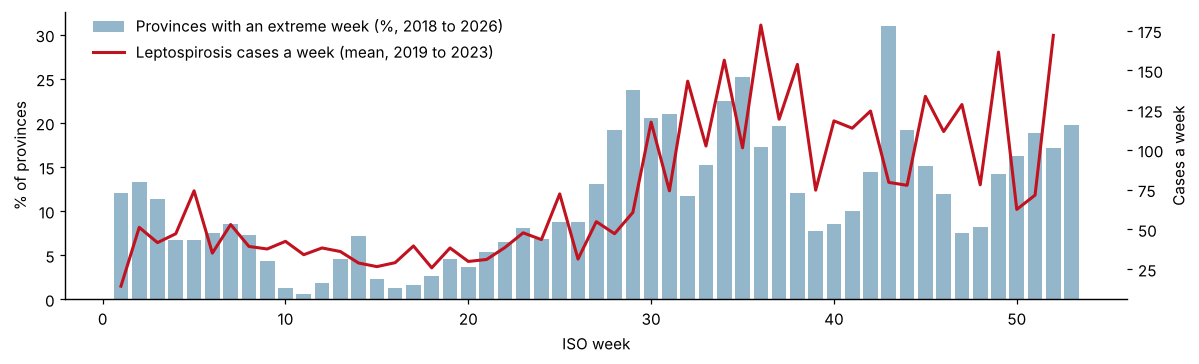

In [15]:
season = c.groupby('iso_week').agg(cases=('cases', 'mean'))
season['share'] = w.groupby('iso_week')['share_prov_above_p90'].mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(season.index, season['share'], color=BLUE, alpha=0.5, label='Provinces with an extreme week (%, 2018 to 2026)')
ax.set(xlabel='ISO week', ylabel='% of provinces')
ax2 = ax.twinx(); ax2.plot(season.index, season['cases'], color=RED, lw=2, label='Leptospirosis cases a week (mean, 2019 to 2023)')
ax2.set_ylabel('Cases a week'); ax2.spines['top'].set_visible(False)
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.98), frameon=False); fig.tight_layout()

**What we saw.** Both series are seasonal. Widespread heavy rain starts around week 27 (early July); cases
start climbing a few weeks later and stay high through December. Cases from January to June average about 40 a
week, against about 120 from August to September.

**How it shaped the work.** Because rain and cases share a season, a simple correlation would find a link even if
rain did nothing. So every model includes **two seasonal harmonics** (notebooks 02 and 05), and the evidence for
rain comes from deviations from the usual season. The storm event study compares each storm with the 4 weeks
just before it, and six other diseases serve as checks (notebook 02).

## 4. A first look: do rain and cases move together?

,raw,after removing season and year
lag_weeks,,
0,0.10,-0.04
1,0.15,0.13
2,0.20,0.18
3,0.24,0.27
4,0.24,0.19
5,0.23,0.14
6,0.21,0.16
7,0.15,0.13
8,0.12,0.08


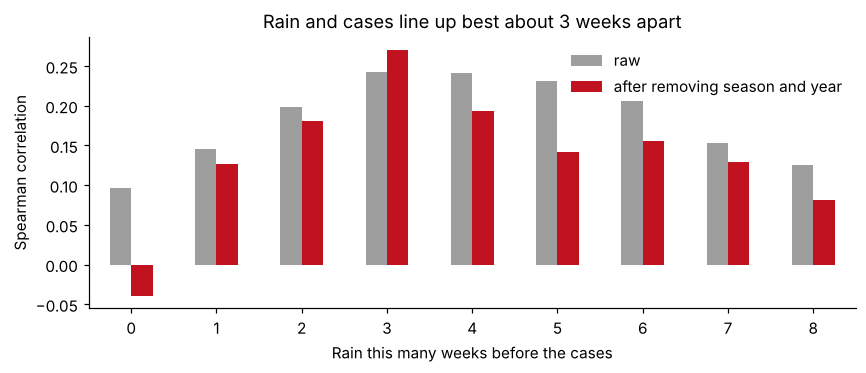

In [16]:
c['log_cases'] = np.log1p(c['cases'])
# Remove each year's level and the usual week-of-year pattern, from both series
c['case_dev'] = c['log_cases'] - c.groupby('iso_year')['log_cases'].transform('mean')
c['case_dev'] -= c.groupby('iso_week')['case_dev'].transform('mean')
w['rain_dev'] = w['share_prov_above_p90'] - w.groupby('iso_week')['share_prov_above_p90'].transform('mean')
rows = []
for L in range(9):
    rows.append({'lag_weeks': L,
                 'raw': c['cases'].corr(w['share_prov_above_p90'].shift(L)[c.index], method='spearman'),
                 'after removing season and year': c['case_dev'].corr(w['rain_dev'].shift(L)[c.index], method='spearman')})
lags = pd.DataFrame(rows).set_index('lag_weeks')
ax = lags.plot.bar(figsize=(9, 3.2), color=[GREY, RED], rot=0)
ax.set(ylabel='Spearman correlation', xlabel='Rain this many weeks before the cases',
       title='Rain and cases line up best about 3 weeks apart'); ax.legend(frameon=False)
lags.round(2)

**What we saw.** Even before any model, the correlation between the rain signal and cases is highest when the
rain is **3 weeks earlier** (about 0.24 raw, 0.27 after removing the season and year levels), and close to zero
for rain in the same week. The correlations are modest, since many other things drive weekly cases.

**How it shaped the work.** This pointed to a lag of a few weeks, so notebook 02 tests every lag from 0 to 8 weeks,
and notebook 05 forecasts with rain 2 to 6 weeks earlier. It also set honest expectations: rain explains part of
the weekly variation, not all of it, which matches the modest forecast gain in notebook 05.

## 5. Barangays

Residents per barangay: 2 to 261,729 (median 2,007); 108 barangays have no area in medium or high zones; 679 are mostly in them; missing values: 0


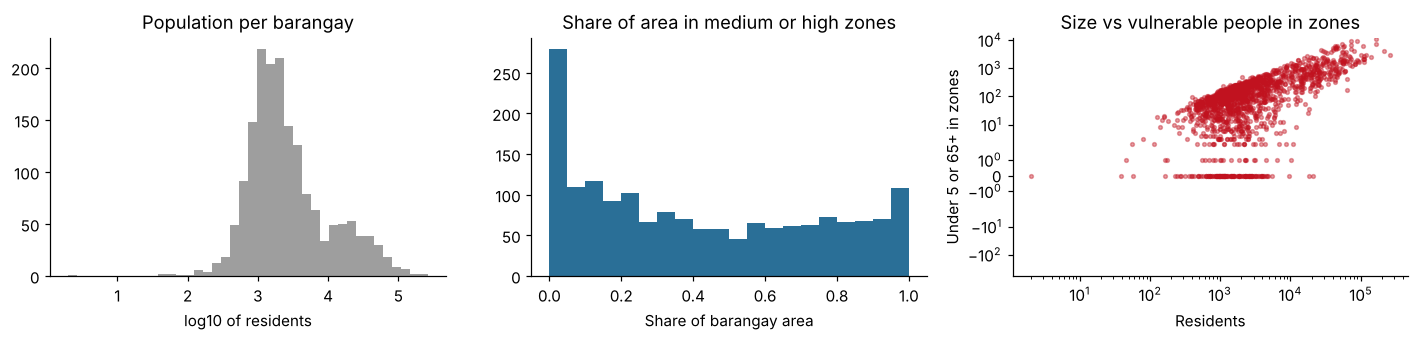

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(np.log10(bgy['population']), bins=40, color=GREY)
ax[0].set(title='Population per barangay', xlabel='log10 of residents')
ax[1].hist(bgy['flood_share_med_high'], bins=20, color=BLUE)
ax[1].set(title='Share of area in medium or high zones', xlabel='Share of barangay area')
ax[2].scatter(bgy['population'], bgy['vulnerable_med_high'], s=6, color=RED, alpha=0.4)
ax[2].set(xscale='log', yscale='symlog', title='Size vs vulnerable people in zones', xlabel='Residents', ylabel='Under 5 or 65+ in zones')
fig.tight_layout()
print(f"Residents per barangay: {bgy['population'].min():,} to {bgy['population'].max():,} (median {bgy['population'].median():,.0f}); "
      f"{(bgy['flood_share_med_high'] == 0).sum()} barangays have no area in medium or high zones; "
      f"{(bgy['flood_share_med_high'] > 0.5).sum()} are mostly in them; missing values: {int(bgy.isna().sum().sum())}")

**What we saw.** Barangays range from a handful of residents to over 260,000, so counts mostly track size.
Flood shares spread across the whole range from 0 to 1: 108 barangays have no area in medium or high zones and
679 are mostly in them. There are no missing values after matching the census to the boundaries (notebook 03).

**How it shaped the work.** A ranking by count alone would always put the biggest barangays first. So the app
ranks three ways (share of residents in zones as the default, number of vulnerable people for supplies, and
vulnerable people per km² for outreach), and estimates people in zones by area share (notebook 03).

## Summary

| What the data showed | How it shaped the work |
| --- | --- |
| Rain is skewed, and normal rain differs by province | Alerts use each place's own 90th percentile; the national signal is the share of provinces above it (01) |
| Case counts are missing for 25 weeks of 2020 and 9 of 2023 | Missing weeks are left out, never set to 0 (01, 02) |
| Year levels shift threefold; counts are overdispersed | Negative binomial with a level per year; checked without 2020 and 2021 (02) |
| The year level is unknown in advance | Backtest scales to recently reported cases, not the test year (05) |
| Rain and cases share a season | Seasonal terms in every model; event study and six other diseases as checks (02) |
| Rain and cases line up best about 3 weeks apart, before any model | Lags 0 to 8 tested (02); forecast uses lags 2 to 6 (05) |
| Barangay sizes vary over 10,000-fold | Three rankings, share of residents in zones by default (03, app) |

In [18]:
matplotlib.rcParams.update(_style_before)   # back to the default chart style for the parts below

---
# Part 4: Lag analysis

*From `notebooks/02_lag_analysis.ipynb`.*

How many weeks after heavy rain do national leptospirosis cases rise? This sets the dashboard's alert window.

**Model.** For each lag L from 0 to 8 weeks, a negative binomial regression of weekly national cases on rainfall
L weeks earlier, with two seasonal harmonics and a dummy for each year (which absorbs the 2020 to 2021 COVID
drop and year-to-year reporting changes). The main rainfall measure is the share of provinces above their own
weekly 90th percentile, scaled per 10 percentage points. Mean weekly rainfall (per 50 mm) is a sensitivity
check, and so is a run without 2020 and 2021. This is a simplified version of the distributed-lag approach
in Matsushita et al. (2018): one lag per model rather than a full lag curve.

Input: `data/processed/weekly_national.csv` from notebook 01. Output: `data/processed/lag_results.csv`.

In [19]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
OUT = ROOT / 'data' / 'processed'
MAX_LAG = 8

w = pd.read_csv(OUT / 'weekly_national.csv').sort_values(['iso_year', 'iso_week']).reset_index(drop=True)
for L in range(MAX_LAG + 1):
    w[f'share_l{L}'] = w['share_prov_above_p90'].shift(L) * 10   # per 10 percentage points
    w[f'mm_l{L}'] = w['mean_rain_mm'].shift(L) / 50              # per 50 mm
for k in (1, 2):
    w[f's{k}'] = np.sin(2 * np.pi * k * w['iso_week'] / 52)
    w[f'c{k}'] = np.cos(2 * np.pi * k * w['iso_week'] / 52)
d = w.dropna(subset=['cases'])
print(len(d), 'weeks with cases,', d['iso_year'].min(), 'to', d['iso_year'].max())

227 weeks with cases, 2019 to 2023


In [20]:
def lag_curve(data, var, label):
    rows = []
    for L in range(MAX_LAG + 1):
        m = smf.negativebinomial(f'cases ~ {var}_l{L} + s1 + c1 + s2 + c2 + C(iso_year)', data).fit(disp=0, maxiter=300)
        b, se = m.params[f'{var}_l{L}'], m.bse[f'{var}_l{L}']
        rows.append({'model': label, 'lag_weeks': L, 'rr': np.exp(b),
                     'rr_low': np.exp(b - 1.96 * se), 'rr_high': np.exp(b + 1.96 * se), 'aic': m.aic})
    return pd.DataFrame(rows)

res = pd.concat([
    lag_curve(d, 'share', 'Main: share of provinces above p90 (per 10 pp)'),
    lag_curve(d, 'mm', 'Sensitivity: mean weekly rain (per 50 mm)'),
    lag_curve(d[~d['iso_year'].isin([2020, 2021])], 'share', 'Sensitivity: main without 2020-2021'),
], ignore_index=True)
res['significant'] = res['rr_low'] > 1
res.round(3).to_csv(OUT / 'lag_results.csv', index=False)
res.round(3)

,model,lag_weeks,rr,rr_low,rr_high,aic,significant
0,Main: share of provinces above p90 (per 10 pp),0,0.982,0.896,1.077,2305.347,False
1,Main: share of provinces above p90 (per 10 pp),1,0.994,0.905,1.092,2305.470,False
2,Main: share of provinces above p90 (per 10 pp),2,1.073,0.978,1.176,2303.152,False
3,Main: share of provinces above p90 (per 10 pp),3,1.170,1.074,1.275,2291.592,True
4,Main: share of provinces above p90 (per 10 pp),4,1.134,1.043,1.234,2296.266,True
5,Main: share of provinces above p90 (per 10 pp),5,1.138,1.052,1.231,2294.567,True
6,Main: share of provinces above p90 (per 10 pp),6,1.122,1.036,1.216,2297.166,True
7,Main: share of provinces above p90 (per 10 pp),7,1.068,0.984,1.160,2302.944,False
8,Main: share of provinces above p90 (per 10 pp),8,1.038,0.950,1.134,2304.798,False
9,Sensitivity: mean weekly rain (per 50 mm),0,0.964,0.719,1.292,2305.426,False


In [21]:
main = res[res['model'].str.startswith('Main')]
peak = main.loc[main['rr'].idxmax()]
sig = main.loc[main['significant'], 'lag_weeks']
print(f"Peak lag: {int(peak.lag_weeks)} weeks, RR {peak.rr:.2f} (95% CI {peak.rr_low:.2f} to {peak.rr_high:.2f}) "
      f"per 10-point rise in the share of provinces with extreme weekly rain.")
print(f"Lags with RR significantly above 1: {sig.min()} to {sig.max()} weeks.")
for name, g in res.groupby('model'):
    print(f"  {name}: peak at {int(g.loc[g['rr'].idxmax(), 'lag_weeks'])} weeks")

Peak lag: 3 weeks, RR 1.17 (95% CI 1.07 to 1.28) per 10-point rise in the share of provinces with extreme weekly rain.
Lags with RR significantly above 1: 3 to 6 weeks.
  Main: share of provinces above p90 (per 10 pp): peak at 3 weeks
  Sensitivity: main without 2020-2021: peak at 3 weeks
  Sensitivity: mean weekly rain (per 50 mm): peak at 3 weeks


In [22]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(main['lag_weeks'], main['rr'], yerr=[main['rr'] - main['rr_low'], main['rr_high'] - main['rr']],
            fmt='o', capsize=3, color='#2a6f97')
ax.axhline(1, color='grey', lw=1)
ax.axvline(2, color='#c1121f', ls='--', lw=1, label='Matsushita et al. (2018): 2 weeks')
ax.set_xlabel('Weeks after heavy rain'); ax.set_ylabel('Relative risk of cases (95% CI)')
ax.set_title('Leptospirosis cases peak about 3 weeks after widespread heavy rain')
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(OUT / 'lag_curve.png', dpi=200)

## Reading the result

The 2-week lag in Matsushita et al. (2018) counts hospital admissions in Manila. The DOH series counts reported
cases by morbidity week, which adds reporting delay, so a peak one week later is consistent with it. Limits:
one national series, 227 usable weeks, missing weeks in 2020 and 2023, and week alignment between CHIRPS dekads
and DOH morbidity weeks is approximate.

## Leptospirosis patterns

Yearly totals and the average week-by-week curve. Cases climb from late July (week 30) and stay high through
December, the typhoon and southwest monsoon season. 2020 and 2021 are low because of COVID-19 disruption.

In [23]:
RAW = ROOT / 'datasets'
dis = pd.read_excel(RAW / 'Diseases Data (for NBL).xlsx').dropna(subset=['Week'])
long = dis.melt(id_vars='Week', var_name='col', value_name='cases')
long['disease'] = long['col'].str.rsplit(' - ', n=1).str[0]
long['iso_year'] = long['col'].str[-4:].astype(int)
long['iso_week'] = long['Week'].astype(int)
long = long[['disease', 'iso_year', 'iso_week', 'cases']]
lep = long[long['disease'] == 'Leptospirosis']
print(lep.groupby('iso_year')['cases'].agg(total='sum', weeks_reported='count'))

           total  weeks_reported
iso_year                        
2019      3278.0              52
2020      1427.0              28
2021      1617.0              52
2022      4773.0              52
2023      5511.0              43


## Storm event study

The heaviest rain weeks of 2019 to 2023 (at least 25% of provinces above their own weekly 90th percentile, events
at least 10 weeks apart). For each, weekly cases from 4 weeks before to 8 weeks after are divided by the average
of the 4 weeks before. The median across events shows the typical response.

In [24]:
ww = w[w['iso_year'].between(2019, 2023)].reset_index(drop=True)
events = []
for i in ww['share_prov_above_p90'].sort_values(ascending=False).index:
    if ww.loc[i, 'share_prov_above_p90'] < 0.25:
        break
    if all(abs(i - j) >= 10 for j in events):
        events.append(i)
rows = []
for i in events:
    base = ww.loc[i - 4:i - 1, 'cases'].mean()
    for k in range(-4, 9):
        if 0 <= i + k < len(ww) and base > 0:
            rows.append({'event_week': ww.loc[i, 'week_start'], 'share_prov_above_p90': ww.loc[i, 'share_prov_above_p90'],
                         'weeks_from_event': k, 'cases': ww.loc[i + k, 'cases'],
                         'ratio_to_before': ww.loc[i + k, 'cases'] / base})
es = pd.DataFrame(rows)
es.round(3).to_csv(OUT / 'event_study.csv', index=False)
print(es['event_week'].nunique(), 'events with case data:', sorted(es['event_week'].unique()))
es.groupby('weeks_from_event')['ratio_to_before'].median().round(2)

11 events with case data: ['2019-08-26', '2020-10-26', '2021-01-11', '2021-07-19', '2021-10-04', '2021-12-13', '2022-04-04', '2022-08-01', '2022-10-24', '2023-01-02', '2023-07-24']


weeks_from_event
-4    1.03
-3    0.54
-2    0.93
-1    1.40
 0    0.59
 1    0.85
 2    1.34
 3    1.98
 4    1.33
 5    1.01
 6    1.02
 7    1.00
 8    0.80
Name: ratio_to_before, dtype: float64

## Negative controls: do other diseases follow rain the same way?

The same model is run for other diseases in the DOH file. Rabies and acute flaccid paralysis have no link to
flooding and serve as negative controls; dengue, typhoid and diarrhoea are water- or rain-related comparisons. If
only leptospirosis shows the 3 to 6 week rise, the result is less likely to be an artefact of seasonality or
reporting.

In [25]:
DISEASES = ['Leptospirosis', 'Dengue', 'Typhoid Fever', 'Acute Bloody Diarrhea', 'Influenza-Like Illness (ILI)',
            'Rabies', 'Acute Flaccid Paralysis (AFP)']
ctl = []
for name in DISEASES:
    dd = w.drop(columns='cases').merge(long[long['disease'] == name], on=['iso_year', 'iso_week'])
    r = lag_curve(dd.dropna(subset=['cases']), 'share', name)
    ctl.append(r.rename(columns={'model': 'disease'}))
ctl = pd.concat(ctl, ignore_index=True)
ctl['significant'] = np.where(ctl['rr_low'] > 1, 'higher', np.where(ctl['rr_high'] < 1, 'lower', ''))
ctl.round(3).to_csv(OUT / 'disease_lag.csv', index=False)
ctl.pivot(index='disease', columns='lag_weeks', values='rr').loc[DISEASES].round(2)

lag_weeks,0,1,2,3,4,5,6,7,8
disease,,,,,,,,,
Leptospirosis,0.98,0.99,1.07,1.17,1.13,1.14,1.12,1.07,1.04
Dengue,0.97,0.92,0.98,0.96,0.94,1.02,1.02,0.99,0.98
Typhoid Fever,0.97,0.90,0.92,0.98,0.98,0.96,1.01,1.03,1.01
Acute Bloody Diarrhea,0.98,0.99,1.01,0.97,0.99,1.01,1.00,0.93,0.94
Influenza-Like Illness (ILI),0.98,0.92,0.94,0.97,0.98,0.98,0.98,1.01,0.97
Rabies,1.02,1.00,1.01,0.99,1.03,1.03,1.02,0.99,0.98
Acute Flaccid Paralysis (AFP),0.95,0.98,1.00,0.97,0.97,1.01,0.99,1.01,0.95


The forecast backtest and the forecast coefficients used by the app are in notebook 05, which tests three models on 2021, 2022 and 2023 without using the test year's case level.

---
# Part 5: Metro Manila outlook

*From `notebooks/04_metro_manila_outlook.ipynb`.*

This notebook looks at what the available data can say about the weeks and months ahead for Metro Manila.

1. **Monthly odds.** From 45 years of CHIRPS 10-day rainfall for NCR (1981 to 2025), the chance that each calendar
   month has at least one 10-day period above the leptospirosis alert threshold (NCR's 90th percentile, 166 mm),
   and above a flood level.
2. **Flood level.** The 10-day rainfall of Metro Manila's major recent floods (Ondoy 2009, Habagat 2012,
   Maring 2013, Habagat 2018, Carina 2024) sets a rain level above which wide flooding is likely. This is a rain
   trigger, not a hydrological flood model.
3. **Inputs for the live forecast.** One point per province, used to fetch a 16-day rainfall forecast from
   Open-Meteo in the app, and a baseline of weekly national cases with no extreme rain (the forecast model of
   notebook 02 with rain set to zero, at the 2023 level), used to turn the expected % rise into cases.

Outputs: `ncr_month_outlook.csv`, `ncr_flood_events.csv`, `province_points.csv`, `weekly_case_baseline.csv`.

In [26]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import numpy as np
import statsmodels.formula.api as smf

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
RAW, OUT = ROOT / 'datasets', ROOT / 'data' / 'processed'
NCR = 'PH13074'

r = pd.read_csv(RAW / 'phl-rainfall-subnat-full.csv', usecols=['date', 'adm_level', 'PCODE', 'rfh'])
r = r[(r['adm_level'] == 2) & (r['PCODE'] == NCR)].copy()
r['date'] = pd.to_datetime(r['date'])
r['year'], r['month'] = r['date'].dt.year, r['date'].dt.month
ALERT = pd.read_csv(OUT / 'dekad_rain.csv').query('PCODE == @NCR')['p90_mm'].iloc[0]
print(len(r), 'NCR 10-day periods,', r['date'].min().date(), 'to', r['date'].max().date(), '| alert threshold', ALERT, 'mm')

1649 NCR 10-day periods, 1981-01-01 to 2026-10-11 | alert threshold 166.39 mm


## Flood level from known floods

Each event is matched to the 10-day period that holds its peak rain day (CHIRPS periods start on the 1st, 11th and
21st of each month).

In [27]:
EVENTS = {'Ondoy (Ketsana), 26 Sep 2009': '2009-09-21', 'Habagat, 7 Aug 2012': '2012-08-01',
          'Maring (Trami), 19 Aug 2013': '2013-08-11', 'Habagat, 11 Aug 2018': '2018-08-11',
          'Carina (Gaemi), 24 Jul 2024': '2024-07-21'}
ev = pd.DataFrame([{'event': k, 'date': pd.Timestamp(d), 'rfh': r.loc[r['date'] == d, 'rfh'].iloc[0]}
                   for k, d in EVENTS.items()])
ev['rfh'] = ev['rfh'].round(0)
ev['percentile'] = ev['rfh'].apply(lambda x: round((r['rfh'] < x).mean() * 100, 1))
FLOOD = float(ev['rfh'].min() // 10 * 10)   # round down to 10 mm
print('Flood level:', FLOOD, 'mm in 10 days; reached in', round((r['rfh'] >= FLOOD).mean() * 100, 1), '% of all periods')
ev

Flood level: 250.0 mm in 10 days; reached in 3.8 % of all periods


,event,date,rfh,percentile
0,"Ondoy (Ketsana), 26 Sep 2009",2009-09-21,313.0,98.9
1,"Habagat, 7 Aug 2012",2012-08-01,637.0,99.9
2,"Maring (Trami), 19 Aug 2013",2013-08-11,308.0,98.8
3,"Habagat, 11 Aug 2018",2018-08-11,259.0,96.8
4,"Carina (Gaemi), 24 Jul 2024",2024-07-21,280.0,97.9


## Monthly odds

Share of years (1981 to 2025) in which the month has at least one 10-day period above each level, for the whole
record and for its two halves, to see whether extremes have become more common.

In [28]:
full = r[r['year'] <= 2025]
def odds(d, level):
    return d.assign(a=d['rfh'] > level).groupby(['year', 'month'])['a'].any().groupby('month').mean()
out = pd.DataFrame({
    'mean_mm_month': full.groupby(['year', 'month'])['rfh'].sum().groupby('month').mean().round(0),
    'chance_alert': odds(full, ALERT), 'chance_flood': odds(full, FLOOD),
    'chance_alert_1981_2003': odds(full[full['year'] <= 2003], ALERT),
    'chance_alert_2004_2025': odds(full[full['year'] >= 2004], ALERT),
}).reset_index()
out['alert_mm'], out['flood_mm'] = ALERT, FLOOD
out.round(2)

,month,mean_mm_month,chance_alert,chance_flood,chance_alert_1981_2003,chance_alert_2004_2025,alert_mm,flood_mm
0,1,24.0,0.00,0.00,0.00,0.00,166.39,250.0
1,2,13.0,0.00,0.00,0.00,0.00,166.39,250.0
2,3,20.0,0.00,0.00,0.00,0.00,166.39,250.0
3,4,26.0,0.00,0.00,0.00,0.00,166.39,250.0
4,5,157.0,0.09,0.04,0.13,0.05,166.39,250.0
5,6,281.0,0.29,0.09,0.26,0.32,166.39,250.0
6,7,447.0,0.69,0.36,0.70,0.68,166.39,250.0
7,8,445.0,0.64,0.27,0.43,0.86,166.39,250.0
8,9,404.0,0.67,0.31,0.57,0.77,166.39,250.0
9,10,247.0,0.22,0.07,0.26,0.18,166.39,250.0


In [29]:
yr = full.assign(a=full['rfh'] > ALERT).groupby('year')['a'].sum()
print('Alert periods per year, 1981-2003:', round(yr[yr.index <= 2003].mean(), 1),
      '| 2004-2025:', round(yr[yr.index >= 2004].mean(), 1))
print('Years with at least one flood-level period:', int((full.groupby('year')['rfh'].max() >= FLOOD).sum()), 'of', full['year'].nunique())

Alert periods per year, 1981-2003: 3.2 | 2004-2025: 4.1
Years with at least one flood-level period: 32 of 45


## Inputs for the live forecast

In [30]:
prov = gpd.read_file(OUT / 'provinces.geojson')
pt = prov.to_crs(32651).representative_point().to_crs(4326)
points = pd.DataFrame({'PCODE': prov['PCODE'], 'lat': pt.y.round(4), 'lon': pt.x.round(4)})

w = pd.read_csv(OUT / 'weekly_national.csv').sort_values(['iso_year', 'iso_week']).reset_index(drop=True)
FC_LAGS = range(2, 7)
for L in FC_LAGS:
    w[f'share_l{L}'] = w['share_prov_above_p90'].shift(L) * 10
for k in (1, 2):
    w[f's{k}'] = np.sin(2 * np.pi * k * w['iso_week'] / 52)
    w[f'c{k}'] = np.cos(2 * np.pi * k * w['iso_week'] / 52)
d = w.dropna(subset=['cases'])
RAIN = ' + '.join(f'share_l{L}' for L in FC_LAGS)
m = smf.negativebinomial(f'cases ~ s1 + c1 + s2 + c2 + C(iso_year) + {RAIN}', d).fit(disp=0, maxiter=500)
X = pd.DataFrame({'iso_week': range(1, 53), 'iso_year': 2023, **{f'share_l{L}': 0.0 for L in FC_LAGS}})
for k in (1, 2):
    X[f's{k}'] = np.sin(2 * np.pi * k * X['iso_week'] / 52)
    X[f'c{k}'] = np.cos(2 * np.pi * k * X['iso_week'] / 52)
base = X[['iso_week']].assign(baseline_cases=m.predict(X).round(1).values)
print(len(points), 'province points; baseline from', len(d), 'weeks of cases:',
      base['baseline_cases'].min(), 'to', base['baseline_cases'].max(), 'cases a week')

81 province points; baseline from 227 weeks of cases: 43.6 to 130.2 cases a week


In [31]:
out.round(3).to_csv(OUT / 'ncr_month_outlook.csv', index=False)
ev.assign(date=ev['date'].dt.date).to_csv(OUT / 'ncr_flood_events.csv', index=False)
points.to_csv(OUT / 'province_points.csv', index=False)
base.to_csv(OUT / 'weekly_case_baseline.csv', index=False)
print('saved')

saved


---
# Part 6: Forecast backtest

*From `notebooks/05_forecast_backtest.ipynb`.*

Can rain help forecast next weeks' national leptospirosis cases? We compare three models, each trained only on
years before the test year and tested on 2021, 2022 and 2023 in turn (rolling origin):

1. **Baseline: seasonal pattern.** Negative binomial with two seasonal harmonics and a year effect.
2. **Seasonal + rain.** The baseline plus the rain signal 2 to 6 weeks earlier (the model used in the app).
3. **Gradient boosting.** A different approach: boosted trees (Poisson loss) on week of year and the same rain lags.

**No peeking at the test year.** The year's overall case level is not known in advance, so every forecast is
scaled to recent cases: the ratio of actual to predicted cases over the 8 weeks that end 2 weeks before the
target week (DOH reports arrive about 2 weeks late). An earlier version scaled to the test year's own average,
which used test data; this notebook replaces it.

Needs only `data/processed/weekly_national.csv` (from notebook 01), so it runs without the raw files.

In [32]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path.cwd().name == 'notebooks' else Path('.')
OUT = ROOT / 'data' / 'processed'
FC_LAGS = range(2, 7)
DELAY, WINDOW = 2, 8          # cases known up to 2 weeks before the target; 8-week scaling window
TEST_YEARS = [2021, 2022, 2023]

w = pd.read_csv(OUT / 'weekly_national.csv').sort_values(['iso_year', 'iso_week']).reset_index(drop=True)
for L in FC_LAGS:
    w[f'share_l{L}'] = w['share_prov_above_p90'].shift(L) * 10   # per 10 percentage points
for k in (1, 2):
    w[f's{k}'] = np.sin(2 * np.pi * k * w['iso_week'] / 52)
    w[f'c{k}'] = np.cos(2 * np.pi * k * w['iso_week'] / 52)
d = w.dropna(subset=['cases'])
RAIN = ' + '.join(f'share_l{L}' for L in FC_LAGS)
BASE = 'cases ~ s1 + c1 + s2 + c2 + C(iso_year)'
GBM_X = ['iso_week'] + [f'share_l{L}' for L in FC_LAGS]
MODELS = ['Baseline: seasonal', 'Seasonal + rain', 'Gradient boosting']
d.groupby('iso_year')['cases'].agg(weeks='count', mean_per_week='mean').round(1)

,weeks,mean_per_week
iso_year,,
2019,52,63.0
2020,28,51.0
2021,52,31.1
2022,52,91.8
2023,43,128.2


In [33]:
def raw_predictions(train, frame):
    """Unscaled predictions of each model for every week in `frame`, using the last training year's level."""
    last = train['iso_year'].max()
    out = pd.DataFrame(index=frame.index)
    for name, f in [(MODELS[0], BASE), (MODELS[1], f'{BASE} + {RAIN}')]:
        m = smf.negativebinomial(f, train).fit(disp=0, maxiter=500)
        out[name] = m.predict(frame.assign(iso_year=last))
    rel = train['cases'] / train.groupby('iso_year')['cases'].transform('mean')
    gbm = HistGradientBoostingRegressor(loss='poisson', max_iter=200, learning_rate=0.05, max_depth=3,
                                        random_state=0).fit(train[GBM_X], rel)
    out[MODELS[2]] = gbm.predict(frame[GBM_X].fillna(0)) * train.loc[train['iso_year'] == last, 'cases'].mean()
    return out


def scale_to_recent(frame, raw, idx):
    """Scale each target week's prediction by actual / predicted cases in the 8 weeks ending 2 weeks before it."""
    rows = []
    for i in idx:
        win = frame.loc[i - DELAY - WINDOW + 1:i - DELAY]
        win = win[win['cases'].notna()]
        row = {}
        for name in MODELS:
            r = win['cases'].sum() / raw.loc[win.index, name].sum() if len(win) >= 4 else 1.0
            row[name] = raw.loc[i, name] * r
        rows.append(row)
    return pd.DataFrame(rows, index=idx)


series, scores = [], []
for year in TEST_YEARS:
    train = d[d['iso_year'] < year]
    frame = w[w['iso_year'] <= year]
    raw = raw_predictions(train, frame)
    idx = frame.index[(frame['iso_year'] == year) & frame['cases'].notna()]
    pred = scale_to_recent(frame, raw, idx)
    y = frame.loc[idx, 'cases']
    after_rain = frame.loc[idx, [f'share_l{L}' for L in FC_LAGS]].max(axis=1) >= 2.5
    for name in MODELS:
        err = (pred[name] - y).abs()
        scores.append({'test_year': year, 'model': name, 'weeks': len(y), 'corr': np.corrcoef(pred[name], y)[0, 1],
                       'mae': err.mean(), 'mae_after_heavy_rain': err[after_rain].mean(),
                       'weeks_after_heavy_rain': int(after_rain.sum())})
    series.append(pd.concat([frame.loc[idx, ['week_start', 'cases']], pred.round(1)], axis=1).assign(test_year=year))

scores = pd.DataFrame(scores)
pooled = (scores.assign(abs_err=scores['mae'] * scores['weeks'])
          .groupby('model', sort=False).agg(weeks=('weeks', 'sum'), abs_err=('abs_err', 'sum')))
pooled['mae'] = pooled['abs_err'] / pooled['weeks']
scores.round(3).to_csv(OUT / 'forecast_scores.csv', index=False)
pd.concat(series).to_csv(OUT / 'forecast_backtest.csv', index=False)
print(pooled[['weeks', 'mae']].round(1))
scores.pivot(index='model', columns='test_year', values=['corr', 'mae']).round(2)

                    weeks   mae
model                          
Baseline: seasonal    147  46.0
Seasonal + rain       147  44.9
Gradient boosting     147  40.8


corr                mae              
test_year           2021  2022  2023   2021   2022   2023
model                                                    
Baseline: seasonal  0.11  0.57  0.68  31.73  57.30  49.59
Gradient boosting   0.05  0.68  0.75  30.88  50.73  40.74
Seasonal + rain     0.17  0.38  0.83  30.00  64.59  39.20

**Reading the result.** Both models that use rain had a lower pooled error than the seasonal baseline (gradient boosting about 41 cases a week, seasonal + rain about 45, baseline about 46), but the gain is small and not steady: seasonal + rain won in 2021 and 2023 and lost in 2022, while gradient boosting won in 2022. With about 230 weeks of national data, the timing evidence (lag model, storm event study, negative controls in notebook 02) is solid, but a week-by-week national count forecast is only indicative. The app uses seasonal + rain because its effect of rain can be read and explained, and it shows this track record next to the forecast.

In [34]:
final = smf.negativebinomial(f'{BASE} + {RAIN}', d).fit(disp=0, maxiter=500)
coef = pd.DataFrame({'lag_weeks': list(FC_LAGS), 'coef': [final.params[f'share_l{L}'] for L in FC_LAGS]})
coef['unit'] = 'per 10 percentage points of provinces above their weekly 90th percentile'
coef.to_csv(OUT / 'forecast_coefs.csv', index=False)
# Overdispersion, used by the app for 80% ranges: variance = mean + alpha * mean^2
pd.DataFrame({'alpha': [final.params['alpha']]}).to_csv(OUT / 'forecast_alpha.csv', index=False)
coef.assign(alpha=final.params['alpha'])

,lag_weeks,coef,unit,alpha
0,2,0.014557,per 10 percentage points of provinces above th...,0.606228
1,3,0.130128,per 10 percentage points of provinces above th...,0.606228
2,4,0.020478,per 10 percentage points of provinces above th...,0.606228
3,5,0.071348,per 10 percentage points of provinces above th...,0.606228
4,6,0.074828,per 10 percentage points of provinces above th...,0.606228
